# 04- Implementación modelos de regresión supervisada

**Proyecto Final Machine Learning**  
Adriana Lorenzo Mingorance

En este notebook vamos a construir distintos modelos de regresión supervisada para predecir la variable: unidades_curriculares_2do_semestestre_califiacion (la media del estudiante en el 2º semestre) . 

Los modelos que vamos a implementar son:
1. 


In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.linear_model import LinearRegression, Ridge, Lasso 
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import cross_val_score



## 1. Carga de datos

In [2]:
X_train = pd.read_csv('../data/X_train_reg.csv')
X_test = pd.read_csv('../data/X_test_reg.csv')


X_train_sc = pd.read_csv('../data/X_train_reg_scaled.csv')
X_test_sc = pd.read_csv('../data/X_test_reg_scaled.csv')

y_train = pd.read_csv('../data/y_train_reg.csv').squeeze()
y_test = pd.read_csv('../data/y_test_reg.csv').squeeze()

print(f"Train: {X_train.shape} | Test: {X_test.shape}")
print(f"Clases: {y_train.value_counts().to_dict()}")

Train: (3539, 232) | Test: (885, 232)
Clases: {0.0: 697, 12.0: 134, 11.0: 126, 13.0: 121, 12.5: 73, 11.5: 70, 14.0: 65, 10.0: 56, 12.666666666666666: 52, 11.333333333333334: 51, 13.5: 50, 12.333333333333334: 45, 11.666666666666666: 44, 11.6: 39, 13.333333333333334: 38, 10.5: 38, 12.8: 37, 11.25: 37, 12.6: 36, 11.8: 36, 13.666666666666666: 35, 12.833333333333334: 35, 12.4: 34, 12.166666666666666: 33, 12.2: 32, 11.4: 30, 14.166666666666666: 28, 11.75: 27, 12.25: 26, 13.2: 26, 10.666666666666666: 22, 12.75: 22, 15.0: 21, 11.2: 21, 13.285714285714286: 19, 13.166666666666666: 19, 11.833333333333334: 19, 14.5: 18, 13.4: 18, 14.333333333333334: 17, 13.25: 17, 10.75: 16, 14.666666666666666: 15, 10.333333333333334: 15, 14.2: 14, 16.0: 14, 13.8: 13, 13.75: 13, 12.428571428571429: 13, 13.6: 13, 13.142857142857142: 12, 13.714285714285714: 12, 12.142857142857142: 12, 14.8: 12, 12.285714285714286: 11, 11.166666666666666: 11, 13.833333333333334: 11, 14.428571428571429: 11, 15.5: 10, 12.85714285714285

Hemos excluido todas las variables del segundo semestre para evitar data leakage, ya que contienen información directamente relacionada con la variable objetivo (nota_media_2sem).


## 2. Distribución del target

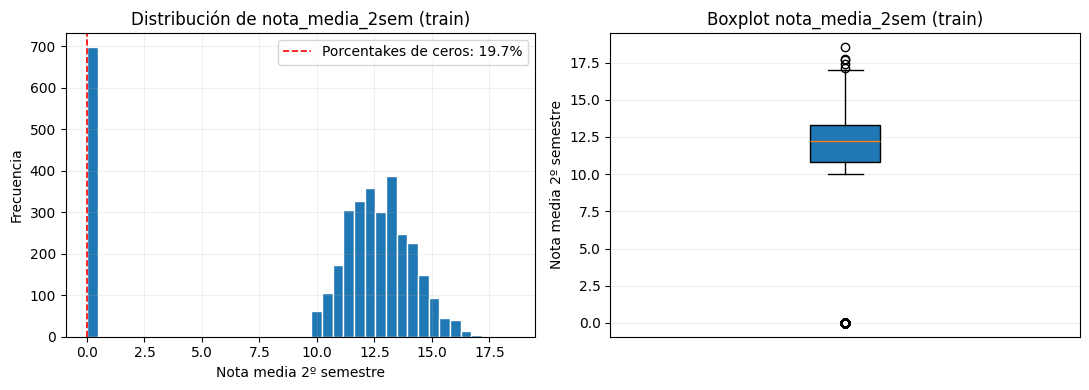

In [5]:
fig, axes = plt.subplots(1,2, figsize=(11, 4))

#histograma del target
axes[0].hist(y_train, bins=40, edgecolor='white')
axes[0].set_title('Distribución de nota_media_2sem (train)')
axes[0].set_xlabel('Nota media 2º semestre')
axes[0].set_ylabel('Frecuencia')
axes[0].grid(alpha=0.2)

#porcentaje de ceros (estudiantes con 0 en todo)
pct_ceros = (y_train == 0).mean() * 100
axes[0].axvline(0, color = 'red', linestyle='--', linewidth=1.2, label = f'Porcentakes de ceros: {pct_ceros:.1f}%')
axes[0].legend()

#boxplot para ver dispersion y posibles outliers
axes[1].boxplot(y_train.dropna(), vert=True, patch_artist=True)
axes[1].set_title('Boxplot nota_media_2sem (train)')
axes[1].set_ylabel('Nota media 2º semestre')
axes[1].set_xticks([])
axes[1].grid(alpha=0.2)

plt.tight_layout()
plt.savefig('../figuras/distribucion_target_reg.png')
plt.show()


Nuestra variable objetivo: nota_media_2sem presenta una distribución asimétrica y un porcentake relevante de valores iguales a cero. Esto puede reflejar casos de abandono temprano o estudiantes no evaluados, lo cual nos añade un reto adicional en la modelizacion a tener en cuenta.

Además, la presencia de posibles outliers y la asimetría de la distribución sugieren que los modelos lineales pueden tener dificultsdes para capturar correctamente la relación entre variables.

## 2. Función de evaluación 

In [10]:
resultados_reg = {}

def evaluar_modelo(nombre, modelo, X_tr, X_test, y_tr, y_test):
    modelo.fit(X_tr, y_tr)
    y_pred = modelo.predict(X_test)

    #usamos las metricas que hemos importdo de sklearn
    rmse = mean_squared_error(y_test, y_pred, squared=False)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    #hacemos validacion cruzada con k= 5 folds, sobre train
    cv_r2 = cross_val_score(modelo, X_tr, y_tr, cv=5, scoring='r2')

    #guardamos los resultados
    resultados_reg[nombre] = {
        'RMSE': round(rmse, 4),
        'MAE': round(mae,4),
        'R2': round(r2, 4),
        'CV R2 (mean)': round(cv_r2.mean(), 4),
        'CV R2 (std)': round(cv_r2.std(), 4)
    }

    print('\n')
    print(f' {nombre}')
    print()
    print(f" RMSE: {rmse:.4f}")
    print(f" MAE: {mae:.4f}")
    print(f" R2: {r2:.4f}")
    print(f" CV R2: {cv_r2.mean():.4f} +/- {cv_r2.std():.4f}")

    return modelo, y_pred